In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from pathlib import Path

data_dir = Path("data")

print("Data folder exists:", data_dir.exists())

if data_dir.exists():
    image_paths = sorted(
        p for p in data_dir.rglob("*")
        if p.is_file() and p.suffix.lower() == ".pgm"
    )

    print("Total face images found:", len(image_paths))
    print("First five image paths:")

    for path in image_paths[:5]:
        print(path)

    print("Subject folders found:",
          len({p.parent for p in image_paths}))

Data folder exists: True
Total face images found: 400
First five image paths:
data\s1\1.pgm
data\s1\10.pgm
data\s1\2.pgm
data\s1\3.pgm
data\s1\4.pgm
Subject folders found: 40


Image path: data\s1\1.pgm
Image dimensions: (92, 112)
Array shape: (112, 92)
Data type: uint8
Minimum pixel intensity: 11
Maximum pixel intensity: 234


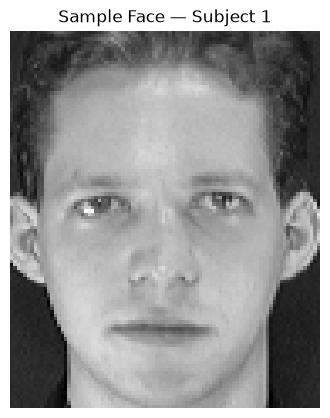

In [4]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Select one face image
image_path = Path("data") / "s1" / "1.pgm"

# Read the image
image = Image.open(image_path).convert("L")

# Convert the image into a NumPy array
image_array = np.array(image)

# Display basic information
print("Image path:", image_path)
print("Image dimensions:", image.size)
print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel intensity:", image_array.min())
print("Maximum pixel intensity:", image_array.max())

# Display the face
plt.figure(figsize=(4, 5))
plt.imshow(image_array, cmap="gray")
plt.title("Sample Face — Subject 1")
plt.axis("off")
plt.show()

In [5]:
# Step 1: Flatten the image matrix into a 1D vector
flat_image = image_array.flatten()

# Step 2: Display the original and flattened shapes
print("Original image shape:", image_array.shape)
print("Flattened vector shape:", flat_image.shape)

# Step 3: Count the number of pixel features
print("Total pixel features:", flat_image.size)

# Step 4: Display the first 20 pixel values
print("First 20 pixel values:", flat_image[:20])

Original image shape: (112, 92)
Flattened vector shape: (10304,)
Total pixel features: 10304
First 20 pixel values: [48 49 45 47 49 57 39 42 53 49 53 60 76 91 99 95 80 75 66 54]


In [6]:
from pathlib import Path
import numpy as np
from PIL import Image

# Step 1: Specify the dataset folder
data_dir = Path("data")

# Step 2: Create empty lists
X_list = []
y_list = []

# Step 3: Visit all 40 subject folders
for subject_id in range(1, 41):

    subject_folder = data_dir / f"s{subject_id}"

    # Step 4: Read the 10 images belonging to this subject
    for image_num in range(1, 11):

        image_path = subject_folder / f"{image_num}.pgm"

        # Step 5: Open the image and convert it to grayscale
        with Image.open(image_path) as img:
            grayscale_image = img.convert("L")
            image_array = np.array(grayscale_image)

        # Step 6: Flatten the image into a feature vector
        flat_image = image_array.flatten()

        # Step 7: Store the features and subject label
        X_list.append(flat_image)
        y_list.append(subject_id)

# Step 8: Convert the lists into NumPy arrays
X = np.array(X_list, dtype=np.uint8)
y = np.array(y_list, dtype=np.int64)

# Step 9: Display dataset information
print("Number of images:", X.shape[0])
print("Number of features per image:", X.shape[1])
print("Image matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Number of subjects:", len(np.unique(y)))

# Step 10: Verify the number of images per subject
subjects, image_counts = np.unique(y, return_counts=True)

print("First five subject image counts:",
      dict(zip(subjects[:5], image_counts[:5])))

print("Does every subject have 10 images?",
      np.all(image_counts == 10))

print("First image label:", y[0])
print("First 10 features of first image:", X[0, :10])

Number of images: 400
Number of features per image: 10304
Image matrix shape: (400, 10304)
Label array shape: (400,)
Number of subjects: 40
First five subject image counts: {np.int64(1): np.int64(10), np.int64(2): np.int64(10), np.int64(3): np.int64(10), np.int64(4): np.int64(10), np.int64(5): np.int64(10)}
Does every subject have 10 images? True
First image label: 1
First 10 features of first image: [48 49 45 47 49 57 39 42 53 49]


In [ ]:
# Create a reproducible stratified split using NumPy only

rng = np.random.default_rng(42)

train_indices = []
test_indices = []

# Split each subject separately
for subject_id in np.unique(y):

    # Find all image indices belonging to this subject
    subject_indices = np.flatnonzero(y == subject_id)

    # Shuffle the indices reproducibly
    subject_indices = rng.permutation(subject_indices)

    # Select 2 images for testing and 8 for training
    test_indices.extend(subject_indices[:2].tolist())
    train_indices.extend(subject_indices[2:].tolist())

# Shuffle the final training and testing index lists
train_indices = rng.permutation(train_indices)
test_indices = rng.permutation(test_indices)

# Build the training and testing arrays
X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

# Verify the split
print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))

print(
    "Training images per subject:",
    np.unique(np.unique(y_train, return_counts=True)[1])
)

print(
    "Testing images per subject:",
    np.unique(np.unique(y_test, return_counts=True)[1])
)

print("Every subject is in both sets:",
      set(y_train) == set(y_test))

Training feature matrix: (320, 10304)
Testing feature matrix: (80, 10304)
Training labels: (320,)
Testing labels: (80,)
Subjects in training: 40
Subjects in testing: 40
Training images per subject: [8]
Testing images per subject: [2]
Every subject is in both sets: True


Mean face vector shape: (10304,)
First 10 mean pixel values: [85.146875 85.234375 85.58125  85.640625 85.703125 86.15625  85.96875
 85.61875  85.890625 85.753125]


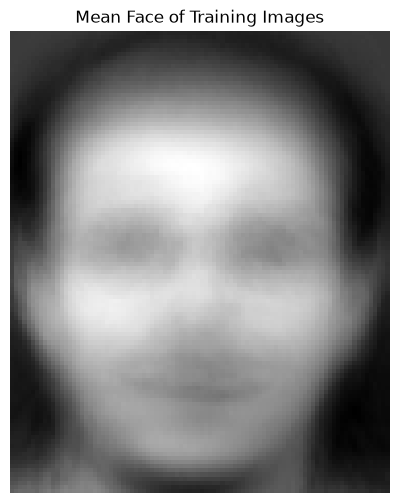

In [8]:
# Step 1: Convert training pixels to floating-point numbers
X_train_float = X_train.astype(np.float64)

# Step 2: Calculate the mean pixel value at each position
mean_face = np.mean(X_train_float, axis=0)

# Step 3: Check the mean face vector
print("Mean face vector shape:", mean_face.shape)
print("First 10 mean pixel values:", mean_face[:10])

# Step 4: Convert the vector back into an image
mean_face_image = mean_face.reshape(112, 92)

# Step 5: Display the mean face
plt.figure(figsize=(5, 6))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face of Training Images")
plt.axis("off")
plt.show()

In [9]:
# Step 1: Subtract the training mean face from training images
X_train_centered = X_train_float - mean_face

# Step 2: Convert test images to floating-point numbers
X_test_float = X_test.astype(np.float64)

# Step 3: Subtract the SAME training mean face from test images
X_test_centered = X_test_float - mean_face

# Step 4: Check the shapes
print("Centered training shape:", X_train_centered.shape)
print("Centered testing shape:", X_test_centered.shape)

# Step 5: Check the average of centered training features
print(
    "Average of centered training features:",
    np.mean(X_train_centered)
)

# Step 6: Check the mean of the first feature
print(
    "Mean of first centered feature:",
    np.mean(X_train_centered[:, 0])
)

Centered training shape: (320, 10304)
Centered testing shape: (80, 10304)
Average of centered training features: 0.0
Mean of first centered feature: 5.684341886080802e-15


In [10]:
# STEP 1: Get the number of training images
n_samples = X_train_centered.shape[0]

print("Number of training images:", n_samples)

# STEP 2: Calculate the sample-space Gram matrix
gram_matrix = X_train_centered @ X_train_centered.T

print("Gram matrix shape:", gram_matrix.shape)

# STEP 3: Calculate eigenvalues and eigenvectors
gram_eigenvalues, gram_eigenvectors = np.linalg.eigh(
    gram_matrix
)

# STEP 4: Sort eigenvalues from largest to smallest
sort_indices = np.argsort(gram_eigenvalues)[::-1]

gram_eigenvalues = gram_eigenvalues[sort_indices]
gram_eigenvectors = gram_eigenvectors[:, sort_indices]

# STEP 5: Remove tiny negative values caused by rounding
gram_eigenvalues = np.maximum(gram_eigenvalues, 0)

# STEP 6: Keep only numerically meaningful eigenvalues
threshold = gram_eigenvalues[0] * 1e-12
valid = gram_eigenvalues > threshold

positive_eigenvalues = gram_eigenvalues[valid]
sample_eigenvectors = gram_eigenvectors[:, valid]

# STEP 7: Recover principal directions in pixel space
eigenface_vectors = (
    X_train_centered.T @ sample_eigenvectors
) / np.sqrt(positive_eigenvalues)

# STEP 8: Calculate covariance eigenvalues
covariance_eigenvalues = (
    positive_eigenvalues / (n_samples - 1)
)

# STEP 9: Display the results
print("Number of retained eigen-directions:",
      len(covariance_eigenvalues))

print("Eigenface vectors shape:", eigenface_vectors.shape)

print("First five covariance eigenvalues:")
print(covariance_eigenvalues[:5])

print("Are eigenvalues in descending order?",
      np.all(np.diff(covariance_eigenvalues) <= 0))

Number of training images: 320
Gram matrix shape: (320, 320)
Number of retained eigen-directions: 319
Eigenface vectors shape: (10304, 319)
First five covariance eigenvalues:
[2881154.3084197  2069914.34945378 1093804.25057136  871380.92597549
  809594.92895779]
Are eigenvalues in descending order? True


In [11]:
# STEP 1: Perform Singular Value Decomposition
U_svd, singular_values, Vt_svd = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

print("U shape:", U_svd.shape)
print("Singular values shape:", singular_values.shape)
print("Vt shape:", Vt_svd.shape)

# STEP 2: Keep numerically meaningful singular values
# Use a threshold consistent with our eigen-decomposition.
svd_valid = (
    singular_values**2
    > singular_values[0]**2 * 1e-12
)

# STEP 3: Recover the principal directions
svd_eigenface_vectors = Vt_svd[svd_valid, :].T

# STEP 4: Calculate covariance eigenvalues from singular values
svd_covariance_eigenvalues = (
    singular_values[svd_valid]**2 / (n_samples - 1)
)

print("Number of SVD directions:", len(svd_covariance_eigenvalues))
print("SVD eigenface vectors shape:", svd_eigenface_vectors.shape)

print("First five SVD covariance eigenvalues:")
print(svd_covariance_eigenvalues[:5])

# STEP 5: Compare eigenvalues from both methods
print(
    "Maximum relative eigenvalue difference:",
    np.max(
        np.abs(covariance_eigenvalues - svd_covariance_eigenvalues)
        / np.maximum(covariance_eigenvalues, 1e-12)
    )
)

# STEP 6: Compare the first ten principal directions
# Absolute dot products account for possible sign changes.
direction_similarity = np.abs(
    np.sum(
        eigenface_vectors[:, :10] * svd_eigenface_vectors[:, :10],
        axis=0
    )
)

print("Similarity of the first 10 directions:")
print(np.round(direction_similarity, 6))

U shape: (320, 320)
Singular values shape: (320,)
Vt shape: (320, 10304)
Number of SVD directions: 319
SVD eigenface vectors shape: (10304, 319)
First five SVD covariance eigenvalues:
[2881154.30841969 2069914.34945378 1093804.25057136  871380.9259755
  809594.92895779]
Maximum relative eigenvalue difference: 1.4108473794901517e-14
Similarity of the first 10 directions:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [12]:
# STEP 1: Calculate the explained variance ratio
explained_variance_ratio = (
    covariance_eigenvalues / np.sum(covariance_eigenvalues)
)

# STEP 2: Calculate cumulative explained variance
cumulative_explained_variance = np.cumsum(
    explained_variance_ratio
)

# STEP 3: Find the minimum components needed for 90% variance
n_components_90 = (
    np.searchsorted(cumulative_explained_variance, 0.90) + 1
)

# STEP 4: Display the results
print("Total PCA components:", len(covariance_eigenvalues))

print("\nExplained variance ratio of first 10 components:")
print(np.round(explained_variance_ratio[:10], 4))

print("\nCumulative explained variance of first 10 components:")
print(np.round(cumulative_explained_variance[:10], 4))

print("\nMinimum components for at least 90% variance:",
      n_components_90)

print("Cumulative variance at selected component count:",
      cumulative_explained_variance[n_components_90 - 1])

print("Original pixel features per face:", X_train.shape[1])

print("Feature-count reduction (%):",
      round((1 - n_components_90 / X_train.shape[1]) * 100, 2))

Total PCA components: 319

Explained variance ratio of first 10 components:
[0.1794 0.1289 0.0681 0.0543 0.0504 0.034  0.025  0.0236 0.0194 0.0183]

Cumulative explained variance of first 10 components:
[0.1794 0.3083 0.3764 0.4307 0.4811 0.5151 0.54   0.5636 0.5831 0.6014]

Minimum components for at least 90% variance: 98
Cumulative variance at selected component count: 0.900585481850082
Original pixel features per face: 10304
Feature-count reduction (%): 99.05


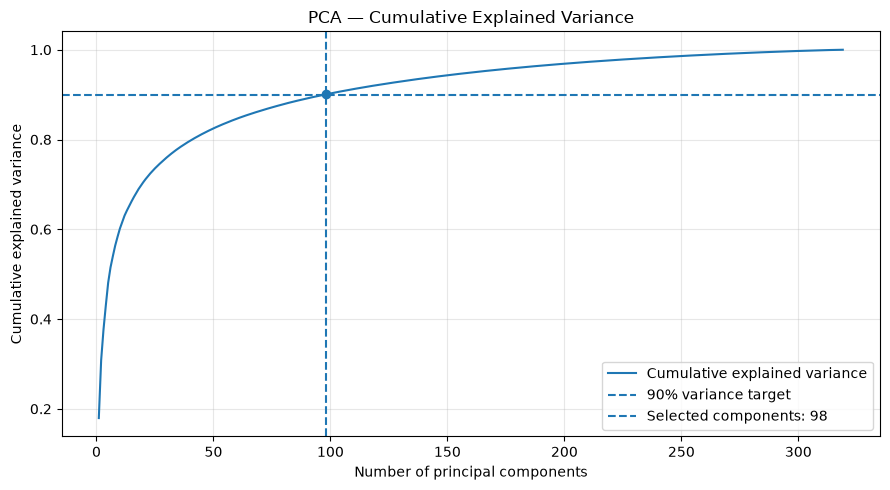

In [13]:
# Components are numbered from 1 to the total number available
components = np.arange(
    1, len(cumulative_explained_variance) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    components,
    cumulative_explained_variance,
    label="Cumulative explained variance"
)

# Target: 90% variance
plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance target"
)

# Mark the minimum component count
plt.axvline(
    x=n_components_90,
    linestyle="--",
    label=f"Selected components: {n_components_90}"
)

plt.scatter(
    n_components_90,
    cumulative_explained_variance[n_components_90 - 1]
)

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA — Cumulative Explained Variance")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

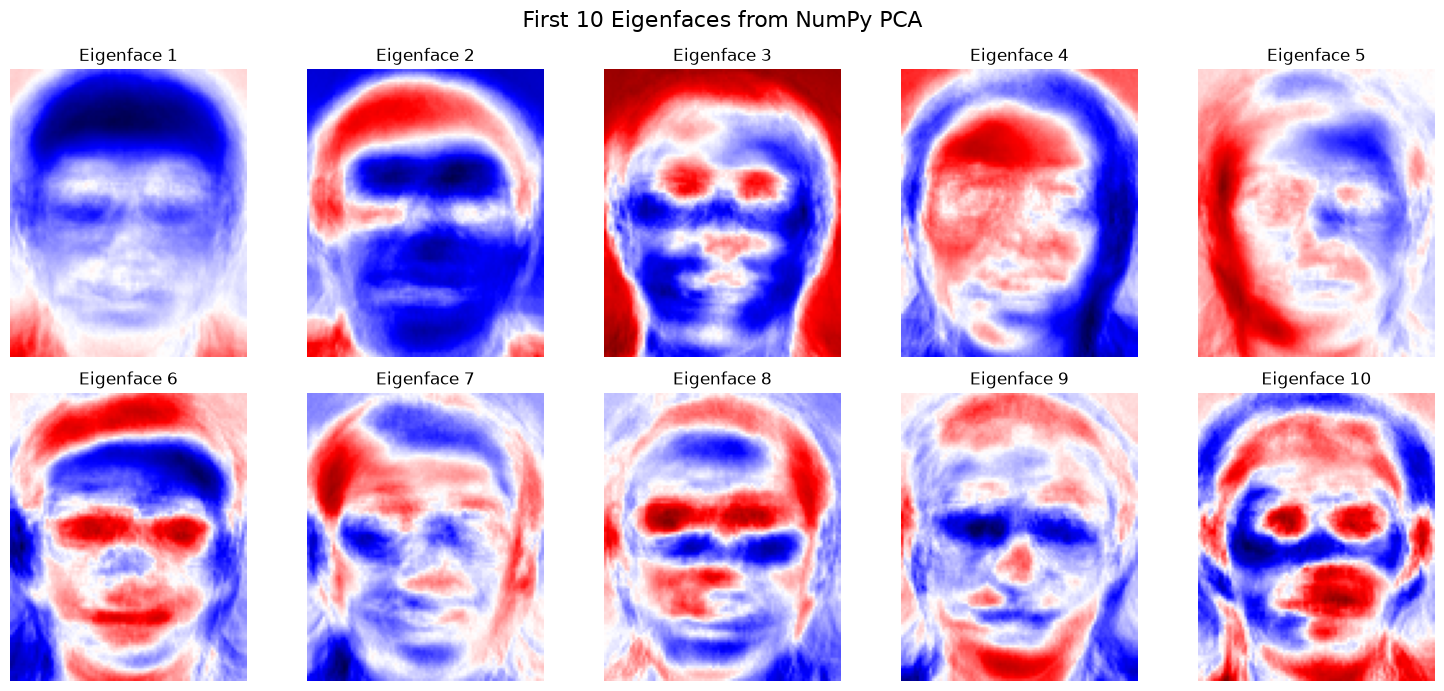

In [14]:
# Number of eigenfaces to display
n_eigenfaces = 10

# Create a grid with 2 rows and 5 columns
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):

    # Extract the i-th principal direction
    eigenface = eigenface_vectors[:, i]

    # Reshape the vector into the original image dimensions
    eigenface_image = eigenface.reshape(112, 92)

    # Use symmetric scaling so positive and negative
    # values are displayed around zero
    scale = np.max(np.abs(eigenface_image))

    ax.imshow(
        eigenface_image,
        cmap="seismic",
        vmin=-scale,
        vmax=scale
    )

    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("First 10 Eigenfaces from NumPy PCA", fontsize=16)
plt.tight_layout()
plt.show()

In [15]:
# Step 1: Select the first 98 principal directions
pca_components = eigenface_vectors[:, :n_components_90]

print("Selected components shape:", pca_components.shape)

# Step 2: Project training images into PCA space
X_train_pca = X_train_centered @ pca_components

# Step 3: Project test images using the SAME components
X_test_pca = X_test_centered @ pca_components

# Step 4: Check the reduced representations
print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_pca.shape)

print("Original testing shape:", X_test.shape)
print("Reduced testing shape:", X_test_pca.shape)

# Step 5: Store the representations and the information
# needed to reproduce the PCA transformation
np.savez_compressed(
    "pca_face_representation.npz",
    X_train_pca=X_train_pca,
    X_test_pca=X_test_pca,
    y_train=y_train,
    y_test=y_test,
    pca_components=pca_components,
    mean_face=mean_face
)

print("Reduced PCA representations saved successfully!")

Selected components shape: (10304, 98)
Original training shape: (320, 10304)
Reduced training shape: (320, 98)
Original testing shape: (80, 10304)
Reduced testing shape: (80, 98)
Reduced PCA representations saved successfully!


Original test matrix shape: (80, 10304)
Reconstructed test matrix shape: (80, 10304)


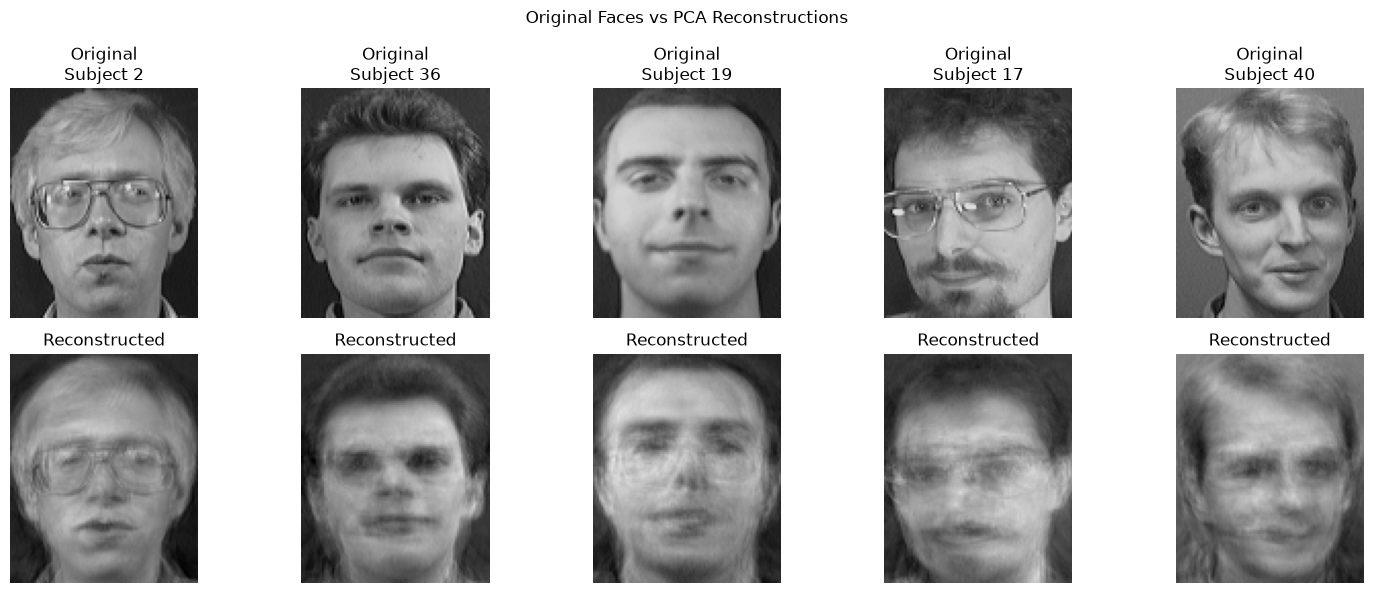

In [16]:
# Step 1: Reconstruct the test images from their PCA scores
X_test_reconstructed = (
    X_test_pca @ pca_components.T
    + mean_face
)

# Step 2: Clip reconstructed pixel values to the valid range
X_test_reconstructed = np.clip(
    X_test_reconstructed, 0, 255
)

print("Original test matrix shape:", X_test.shape)
print("Reconstructed test matrix shape:",
      X_test_reconstructed.shape)

# Step 3: Display five original and reconstructed faces
n_show = 5

fig, axes = plt.subplots(
    2, n_show, figsize=(15, 6)
)

for i in range(n_show):

    # Original face
    axes[0, i].imshow(
        X_test[i].reshape(112, 92),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, i].set_title(
        f"Original\nSubject {y_test[i]}"
    )
    axes[0, i].axis("off")

    # Reconstructed face
    axes[1, i].imshow(
        X_test_reconstructed[i].reshape(112, 92),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle("Original Faces vs PCA Reconstructions")
plt.tight_layout()
plt.show()

In [17]:
# Step 1: Calculate pixel reconstruction errors
pixel_errors = (
    X_test.astype(np.float64)
    - X_test_reconstructed
)

# Step 2: Calculate mean squared error
mse = np.mean(pixel_errors ** 2)

# Step 3: Calculate root mean squared error
rmse = np.sqrt(mse)

# Step 4: Calculate PSNR for 8-bit grayscale images
if mse == 0:
    psnr = float("inf")
else:
    psnr = 10 * np.log10((255 ** 2) / mse)

print("Reconstruction MSE:", mse)
print("Reconstruction RMSE:", rmse)
print("Reconstruction PSNR (dB):", psnr)

Reconstruction MSE: 329.9535055480563
Reconstruction RMSE: 18.164622361834454
Reconstruction PSNR (dB): 22.946276140400844


In [18]:
# Original pixel storage for the training images
original_bytes = X_train.nbytes

# Storage for PCA training scores only
reduced_bytes = X_train_pca.nbytes

# Shared model storage: components and mean face
model_bytes = (
    pca_components.nbytes
    + mean_face.nbytes
)

print("Original training pixels (bytes):", original_bytes)
print("Reduced PCA scores (bytes):", reduced_bytes)

print("Original bytes per image:", X_train[0].nbytes)
print("Reduced bytes per image:", X_train_pca[0].nbytes)

print(
    "Per-image feature payload reduction (%):",
    round((1 - X_train_pca[0].nbytes / X_train[0].nbytes)
          * 100, 2)
)

print("Shared PCA model size (bytes):", model_bytes)

print(
    "Reduced scores + shared PCA model (bytes):",
    reduced_bytes + model_bytes
)

Original training pixels (bytes): 3297280
Reduced PCA scores (bytes): 250880
Original bytes per image: 10304
Reduced bytes per image: 784
Per-image feature payload reduction (%): 92.39
Shared PCA model size (bytes): 8160768
Reduced scores + shared PCA model (bytes): 8411648


In [19]:
# STEP 1: Convert pixel values to floating-point numbers
X_train_raw = X_train.astype(np.float64)
X_test_raw = X_test.astype(np.float64)

# STEP 2: Calculate squared lengths of all training images
train_squared_norms = np.sum(X_train_raw ** 2, axis=1)

# STEP 3: Calculate squared lengths of all test images
test_squared_norms = np.sum(X_test_raw ** 2, axis=1)

# STEP 4: Calculate squared Euclidean distances efficiently
squared_distances = (
    test_squared_norms[:, np.newaxis]
    + train_squared_norms[np.newaxis, :]
    - 2 * (X_test_raw @ X_train_raw.T)
)

# Correct tiny negative values caused by floating-point rounding
np.maximum(squared_distances, 0, out=squared_distances)

print("Distance matrix shape:", squared_distances.shape)

# STEP 5: Find the nearest training face for each test image
nearest_train_indices = np.argmin(squared_distances, axis=1)

# STEP 6: Assign the label of the nearest training face
y_pred_raw = y_train[nearest_train_indices]

# STEP 7: Calculate recognition accuracy manually
correct_predictions = np.sum(y_pred_raw == y_test)
total_test_images = len(y_test)

raw_pixel_accuracy = correct_predictions / total_test_images

print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", total_test_images - correct_predictions)
print("Total test images:", total_test_images)
print("Raw-pixel recognition accuracy:",
      round(raw_pixel_accuracy * 100, 2), "%")

# STEP 8: Show the first 10 predictions
nearest_distances = np.sqrt(
    squared_distances[
        np.arange(total_test_images),
        nearest_train_indices
    ]
)

print("\nFirst 10 recognition results:")

for i in range(min(10, total_test_images)):
    result = "Correct" if y_pred_raw[i] == y_test[i] else "Incorrect"

    print(
        f"Test image {i + 1}: "
        f"Actual subject = {y_test[i]}, "
        f"Predicted subject = {y_pred_raw[i]}, "
        f"Distance = {nearest_distances[i]:.2f}, "
        f"Result = {result}"
    )

Distance matrix shape: (80, 320)
Correct predictions: 76
Incorrect predictions: 4
Total test images: 80
Raw-pixel recognition accuracy: 95.0 %

First 10 recognition results:
Test image 1: Actual subject = 2, Predicted subject = 2, Distance = 2252.94, Result = Correct
Test image 2: Actual subject = 36, Predicted subject = 36, Distance = 2686.96, Result = Correct
Test image 3: Actual subject = 19, Predicted subject = 19, Distance = 1427.67, Result = Correct
Test image 4: Actual subject = 17, Predicted subject = 17, Distance = 2671.14, Result = Correct
Test image 5: Actual subject = 40, Predicted subject = 40, Distance = 3098.87, Result = Correct
Test image 6: Actual subject = 24, Predicted subject = 24, Distance = 2803.42, Result = Correct
Test image 7: Actual subject = 33, Predicted subject = 33, Distance = 2473.92, Result = Correct
Test image 8: Actual subject = 20, Predicted subject = 20, Distance = 3142.46, Result = Correct
Test image 9: Actual subject = 4, Predicted subject = 4, Dis

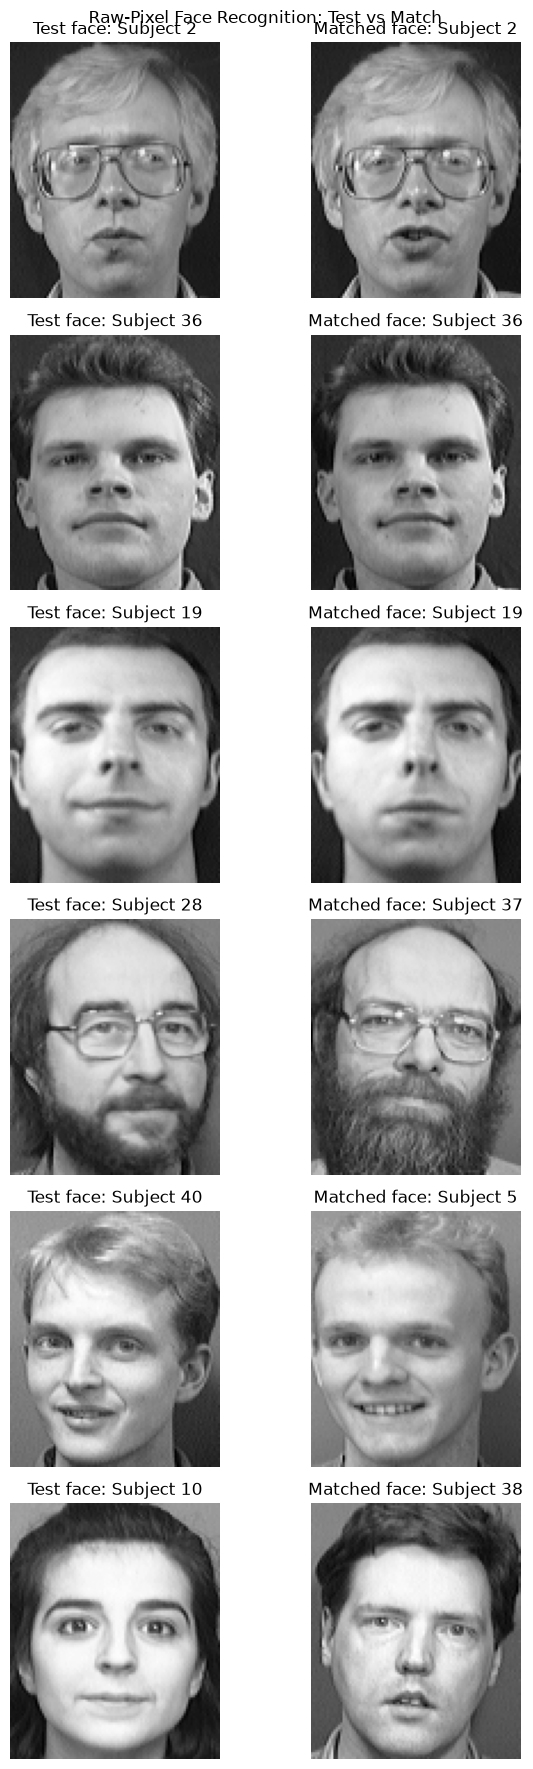

In [20]:
# Select up to 3 correct and 3 incorrect predictions
correct_indices = np.where(y_pred_raw == y_test)[0][:3]
incorrect_indices = np.where(y_pred_raw != y_test)[0][:3]

selected_indices = np.concatenate(
    [correct_indices, incorrect_indices]
)

if len(selected_indices) == 0:
    print("No test images available to visualize.")
else:
    fig, axes = plt.subplots(
        len(selected_indices), 2,
        figsize=(7, 3 * len(selected_indices)),
        squeeze=False
    )

    for row, test_idx in enumerate(selected_indices):

        # Original test face
        axes[row, 0].imshow(
            X_test[test_idx].reshape(112, 92),
            cmap="gray"
        )
        axes[row, 0].set_title(
            f"Test face: Subject {y_test[test_idx]}"
        )
        axes[row, 0].axis("off")

        # Closest stored training face
        train_idx = nearest_train_indices[test_idx]

        axes[row, 1].imshow(
            X_train[train_idx].reshape(112, 92),
            cmap="gray"
        )
        axes[row, 1].set_title(
            f"Matched face: Subject {y_pred_raw[test_idx]}"
        )
        axes[row, 1].axis("off")

    plt.suptitle("Raw-Pixel Face Recognition: Test vs Match")
    plt.tight_layout()
    plt.show()

In [21]:
# STEP 1: Calculate squared lengths of PCA training vectors
train_pca_squared_norms = np.sum(
    X_train_pca ** 2,
    axis=1
)

# STEP 2: Calculate squared lengths of PCA test vectors
test_pca_squared_norms = np.sum(
    X_test_pca ** 2,
    axis=1
)

# STEP 3: Calculate all pairwise squared Euclidean distances
pca_squared_distances = (
    test_pca_squared_norms[:, np.newaxis]
    + train_pca_squared_norms[np.newaxis, :]
    - 2 * (X_test_pca @ X_train_pca.T)
)

# Remove tiny negative values caused by rounding
np.maximum(pca_squared_distances, 0, out=pca_squared_distances)

print("PCA distance matrix shape:", pca_squared_distances.shape)

# STEP 4: Find the nearest training image for each test image
nearest_pca_indices = np.argmin(
    pca_squared_distances,
    axis=1
)

# STEP 5: Predict the subject using the nearest training image
y_pred_pca = y_train[nearest_pca_indices]

# STEP 6: Calculate PCA recognition accuracy
pca_correct = np.sum(y_pred_pca == y_test)
pca_incorrect = len(y_test) - pca_correct

pca_accuracy = pca_correct / len(y_test)

print("Correct PCA predictions:", pca_correct)
print("Incorrect PCA predictions:", pca_incorrect)
print("Total test images:", len(y_test))
print(
    "PCA recognition accuracy:",
    round(pca_accuracy * 100, 2), "%"
)

# STEP 7: Show the first 10 PCA recognition results
nearest_pca_distances = np.sqrt(
    pca_squared_distances[
        np.arange(len(y_test)),
        nearest_pca_indices
    ]
)

print("\nFirst 10 PCA recognition results:")

for i in range(min(10, len(y_test))):
    result = (
        "Correct"
        if y_pred_pca[i] == y_test[i]
        else "Incorrect"
    )

    print(
        f"Test image {i + 1}: "
        f"Actual = {y_test[i]}, "
        f"Predicted = {y_pred_pca[i]}, "
        f"Distance = {nearest_pca_distances[i]:.2f}, "
        f"Result = {result}"
    )

PCA distance matrix shape: (80, 320)
Correct PCA predictions: 76
Incorrect PCA predictions: 4
Total test images: 80
PCA recognition accuracy: 95.0 %

First 10 PCA recognition results:
Test image 1: Actual = 2, Predicted = 2, Distance = 986.68, Result = Correct
Test image 2: Actual = 36, Predicted = 36, Distance = 1625.86, Result = Correct
Test image 3: Actual = 19, Predicted = 19, Distance = 799.34, Result = Correct
Test image 4: Actual = 17, Predicted = 17, Distance = 1332.70, Result = Correct
Test image 5: Actual = 40, Predicted = 40, Distance = 2018.37, Result = Correct
Test image 6: Actual = 24, Predicted = 24, Distance = 2093.50, Result = Correct
Test image 7: Actual = 33, Predicted = 33, Distance = 1552.25, Result = Correct
Test image 8: Actual = 20, Predicted = 20, Distance = 1976.69, Result = Correct
Test image 9: Actual = 4, Predicted = 4, Distance = 2713.38, Result = Correct
Test image 10: Actual = 35, Predicted = 35, Distance = 1701.50, Result = Correct


In [24]:
import pandas as pd
import numpy as np

# Step 1: Count correct predictions for each method
raw_correct = int(np.sum(y_pred_raw == y_test))
pca_correct = int(np.sum(y_pred_pca == y_test))

# Step 2: Calculate accuracy manually
raw_accuracy = raw_correct / len(y_test) * 100
pca_accuracy = pca_correct / len(y_test) * 100

# Step 3: Build the comparison table
comparison_df = pd.DataFrame({
    "Method": [
        "Raw-pixel nearest neighbor",
        "PCA nearest neighbor (98 components)"
    ],
    "Features per image": [
        X_train.shape[1],
        X_train_pca.shape[1]
    ],
    "Correct predictions": [
        raw_correct,
        pca_correct
    ],
    "Incorrect predictions": [
        len(y_test) - raw_correct,
        len(y_test) - pca_correct
    ],
    "Accuracy (%)": [
        round(raw_accuracy, 2),
        round(pca_accuracy, 2)
    ]
})

display(comparison_df)

,Method,Features per image,Correct predictions,Incorrect predictions,Accuracy (%)
0,Raw-pixel nearest neighbor,10304,76,4,95.0
1,PCA nearest neighbor (98 components),98,76,4,95.0


In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# -----------------------------------------
# MODEL 1: K-Nearest Neighbors (KNN)
# -----------------------------------------

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=3,
        weights="distance"
    )
)

# Learn from training PCA features
knn_model.fit(X_train_pca, y_train)

# Predict identities of test faces
y_pred_knn = knn_model.predict(X_test_pca)

# Evaluate KNN
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Results")
print("Correct predictions:", np.sum(y_pred_knn == y_test))
print("Incorrect predictions:", np.sum(y_pred_knn != y_test))
print("Accuracy:", round(knn_accuracy * 100, 2), "%")


# -----------------------------------------
# MODEL 2: Support Vector Machine (SVM)
# -----------------------------------------

svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale"
    )
)

# Learn from training PCA features
svm_model.fit(X_train_pca, y_train)

# Predict identities of test faces
y_pred_svm = svm_model.predict(X_test_pca)

# Evaluate SVM
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("\nSVM Results")
print("Correct predictions:", np.sum(y_pred_svm == y_test))
print("Incorrect predictions:", np.sum(y_pred_svm != y_test))
print("Accuracy:", round(svm_accuracy * 100, 2), "%")

KNN Results
Correct predictions: 62
Incorrect predictions: 18
Accuracy: 77.5 %

SVM Results
Correct predictions: 76
Incorrect predictions: 4
Accuracy: 95.0 %


In [26]:
# Compare all four recognition methods

methods = [
    "Raw-pixel nearest neighbor",
    "PCA nearest neighbor (98 components)",
    "KNN (PCA features)",
    "SVM (PCA features)"
]

predictions = [
    y_pred_raw,
    y_pred_pca,
    y_pred_knn,
    y_pred_svm
]

feature_counts = [
    X_train.shape[1],
    X_train_pca.shape[1],
    X_train_pca.shape[1],
    X_train_pca.shape[1]
]

correct_counts = [
    int(np.sum(pred == y_test))
    for pred in predictions
]

incorrect_counts = [
    len(y_test) - count
    for count in correct_counts
]

accuracies = [
    round(count / len(y_test) * 100, 2)
    for count in correct_counts
]

final_comparison = pd.DataFrame({
    "Method": methods,
    "Features per image": feature_counts,
    "Correct predictions": correct_counts,
    "Incorrect predictions": incorrect_counts,
    "Accuracy (%)": accuracies
})

display(final_comparison)

,Method,Features per image,Correct predictions,Incorrect predictions,Accuracy (%)
0,Raw-pixel nearest neighbor,10304,76,4,95.0
1,PCA nearest neighbor (98 components),98,76,4,95.0
2,KNN (PCA features),98,62,18,77.5
3,SVM (PCA features),98,76,4,95.0


In [27]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

# Use the same reproducible cross-validation folds
cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# --------------------------------------------------
# EXPERIMENT 1: KNN WITHOUT FEATURE SCALING
# --------------------------------------------------

knn_unscaled_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid={
        "n_neighbors": [1, 3, 5, 7, 9],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

knn_unscaled_search.fit(X_train_pca, y_train)


# --------------------------------------------------
# EXPERIMENT 2: KNN WITH FEATURE SCALING
# --------------------------------------------------

knn_scaled_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    ),
    param_grid={
        "kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9],
        "kneighborsclassifier__weights": ["uniform", "distance"],
        "kneighborsclassifier__p": [1, 2]
    },
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

knn_scaled_search.fit(X_train_pca, y_train)


# --------------------------------------------------
# EXPERIMENT 3: TUNE SVM
# --------------------------------------------------

svm_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),
    param_grid={
        "svc__C": [0.1, 1, 10, 100],
        "svc__gamma": ["scale", 0.001, 0.01, 0.1]
    },
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

svm_search.fit(X_train_pca, y_train)


# --------------------------------------------------
# DISPLAY CROSS-VALIDATION RESULTS
# --------------------------------------------------

search_results = pd.DataFrame([
    {
        "Model": "KNN unscaled",
        "Best CV accuracy (%)": round(
            knn_unscaled_search.best_score_ * 100, 2
        ),
        "Best settings": str(knn_unscaled_search.best_params_)
    },
    {
        "Model": "KNN scaled",
        "Best CV accuracy (%)": round(
            knn_scaled_search.best_score_ * 100, 2
        ),
        "Best settings": str(knn_scaled_search.best_params_)
    },
    {
        "Model": "SVM",
        "Best CV accuracy (%)": round(
            svm_search.best_score_ * 100, 2
        ),
        "Best settings": str(svm_search.best_params_)
    }
])

display(search_results)


# --------------------------------------------------
# EVALUATE THE SELECTED SETTINGS ON THE TEST SET
# --------------------------------------------------

knn_candidates = [
    ("Tuned KNN (unscaled)", knn_unscaled_search),
    ("Tuned KNN (scaled)", knn_scaled_search)
]

best_knn_name, best_knn_search = max(
    knn_candidates,
    key=lambda item: item[1].best_score_
)

y_pred_knn_tuned = best_knn_search.predict(X_test_pca)
y_pred_svm_tuned = svm_search.predict(X_test_pca)

print("Selected KNN:", best_knn_name)
print("Selected KNN settings:", best_knn_search.best_params_)
print(
    "Selected KNN test accuracy:",
    round(accuracy_score(y_test, y_pred_knn_tuned) * 100, 2),
    "%"
)

print("\nSelected SVM settings:", svm_search.best_params_)
print(
    "Selected SVM test accuracy:",
    round(accuracy_score(y_test, y_pred_svm_tuned) * 100, 2),
    "%"
)

,Model,Best CV accuracy (%),Best settings
0,KNN unscaled,97.19,"{'n_neighbors': 1, 'p': 2, 'weights': 'uniform'}"
1,KNN scaled,85.62,"{'kneighborsclassifier__n_neighbors': 1, 'knei..."
2,SVM,89.38,"{'svc__C': 10, 'svc__gamma': 0.001}"


Selected KNN: Tuned KNN (unscaled)
Selected KNN settings: {'n_neighbors': 1, 'p': 2, 'weights': 'uniform'}
Selected KNN test accuracy: 95.0 %

Selected SVM settings: {'svc__C': 10, 'svc__gamma': 0.001}
Selected SVM test accuracy: 93.75 %


In [28]:
from sklearn.metrics import accuracy_score

# Evaluate the selected KNN model
y_pred_knn_tuned = knn_unscaled_search.best_estimator_.predict(
    X_test_pca
)

# Evaluate the selected SVM model
y_pred_svm_tuned = svm_search.best_estimator_.predict(
    X_test_pca
)

print(
    "Tuned KNN test accuracy:",
    round(accuracy_score(y_test, y_pred_knn_tuned) * 100, 2),
    "%"
)

print(
    "Tuned SVM test accuracy:",
    round(accuracy_score(y_test, y_pred_svm_tuned) * 100, 2),
    "%"
)

Tuned KNN test accuracy: 95.0 %
Tuned SVM test accuracy: 93.75 %


In [29]:
import pandas as pd
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Number of PCA components to test
component_counts = [25, 50, 75, 98, 125, 150]

results = []

for k in component_counts:

    print(f"Testing {k} PCA components...")

    # Step 1: Select the first k PCA directions
    components_k = eigenface_vectors[:, :k]

    # Step 2: Project training and testing images
    X_train_k = X_train_centered @ components_k
    X_test_k = X_test_centered @ components_k

    # Step 3: Calculate cumulative explained variance
    variance_preserved = cumulative_explained_variance[k - 1]

    # Step 4: Nearest-neighbor recognition
    nearest_model = KNeighborsClassifier(
        n_neighbors=1,
        metric="euclidean"
    )

    nearest_model.fit(X_train_k, y_train)
    pred_nearest = nearest_model.predict(X_test_k)

    # Step 5: KNN with 3 neighbors and standardized features
    knn_model_k = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=3,
            weights="distance",
            p=2
        )
    )

    knn_model_k.fit(X_train_k, y_train)
    pred_knn = knn_model_k.predict(X_test_k)

    # Step 6: SVM with the best settings from the search
    svm_model_k = make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=svm_search.best_params_["svc__C"],
            gamma=svm_search.best_params_["svc__gamma"]
        )
    )

    svm_model_k.fit(X_train_k, y_train)
    pred_svm = svm_model_k.predict(X_test_k)

    # Step 7: Save the results
    results.append({
        "Components": k,
        "Variance preserved (%)": round(
            variance_preserved * 100, 2
        ),
        "Nearest neighbor (%)": round(
            accuracy_score(y_test, pred_nearest) * 100, 2
        ),
        "KNN (3 neighbors) (%)": round(
            accuracy_score(y_test, pred_knn) * 100, 2
        ),
        "SVM (%)": round(
            accuracy_score(y_test, pred_svm) * 100, 2
        )
    })

# Display the complete component-count comparison
component_results_df = pd.DataFrame(results)

display(component_results_df)

Testing 25 PCA components...
Testing 50 PCA components...
Testing 75 PCA components...
Testing 98 PCA components...
Testing 125 PCA components...
Testing 150 PCA components...


,Components,Variance preserved (%),Nearest neighbor (%),KNN (3 neighbors) (%),SVM (%)
0,25,73.57,95.00,90.00,91.25
1,50,82.48,96.25,92.50,95.00
2,75,87.16,95.00,85.00,95.00
3,98,90.06,95.00,77.50,93.75
4,125,92.54,96.25,68.75,93.75
5,150,94.31,95.00,61.25,93.75


In [30]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Output folder:", output_dir.resolve())

Output folder: D:\documents\202618045_Lab_7\outputs


In [35]:
print("Files saved in outputs:")

for file_path in sorted(output_dir.iterdir()):
    print(file_path.name, "-", file_path.stat().st_size, "bytes")
    

Files saved in outputs:
cumulative_explained_variance.png - 130877 bytes
eigenfaces.png - 311059 bytes
recognition_examples.png - 455178 bytes
reconstruction_examples.png - 336402 bytes


In [36]:
import numpy as np
import pandas as pd
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# All recognition methods and their predictions
model_predictions = {
    "Raw-pixel nearest neighbor": y_pred_raw,
    "PCA nearest neighbor (98 components)": y_pred_pca,
    "KNN baseline (scaled, k=3)": y_pred_knn,
    "SVM baseline": y_pred_svm,
    "Tuned KNN": y_pred_knn_tuned,
    "Tuned SVM": y_pred_svm_tuned
}

# Number of input features per image
feature_counts = {
    "Raw-pixel nearest neighbor": X_train.shape[1],
    "PCA nearest neighbor (98 components)": X_train_pca.shape[1],
    "KNN baseline (scaled, k=3)": X_train_pca.shape[1],
    "SVM baseline": X_train_pca.shape[1],
    "Tuned KNN": X_train_pca.shape[1],
    "Tuned SVM": X_train_pca.shape[1]
}

# Calculate final test metrics
rows = []

for method, predictions in model_predictions.items():
    correct = int(np.sum(predictions == y_test))

    rows.append({
        "Method": method,
        "Features per image": feature_counts[method],
        "Correct predictions": correct,
        "Incorrect predictions": len(y_test) - correct,
        "Accuracy (%)": round(correct / len(y_test) * 100, 2)
    })

final_results_df = pd.DataFrame(rows)

# Save the comparison table
final_results_df.to_csv(
    output_dir / "final_model_comparison.csv",
    index=False
)

display(final_results_df)

print("Saved: outputs/final_model_comparison.csv")

,Method,Features per image,Correct predictions,Incorrect predictions,Accuracy (%)
0,Raw-pixel nearest neighbor,10304,76,4,95.00
1,PCA nearest neighbor (98 components),98,76,4,95.00
2,"KNN baseline (scaled, k=3)",98,62,18,77.50
3,SVM baseline,98,76,4,95.00
4,Tuned KNN,98,76,4,95.00
5,Tuned SVM,98,75,5,93.75


Saved: outputs/final_model_comparison.csv


In [37]:
recognition_results_df = pd.DataFrame({
    "Test image index": np.arange(1, len(y_test) + 1),
    "Actual subject": y_test,

    "Raw-pixel prediction": y_pred_raw,
    "Raw-pixel distance": nearest_distances,
    "Raw-pixel correct": y_pred_raw == y_test,

    "PCA prediction": y_pred_pca,
    "PCA distance": nearest_pca_distances,
    "PCA correct": y_pred_pca == y_test,

    "KNN baseline prediction": y_pred_knn,
    "KNN baseline correct": y_pred_knn == y_test,

    "SVM baseline prediction": y_pred_svm,
    "SVM baseline correct": y_pred_svm == y_test,

    "Tuned KNN prediction": y_pred_knn_tuned,
    "Tuned KNN correct": y_pred_knn_tuned == y_test,

    "Tuned SVM prediction": y_pred_svm_tuned,
    "Tuned SVM correct": y_pred_svm_tuned == y_test
})

recognition_results_df.to_csv(
    output_dir / "recognition_predictions.csv",
    index=False
)

display(recognition_results_df.head(10))

print("Saved: outputs/recognition_predictions.csv")

,Test image index,Actual subject,Raw-pixel prediction,Raw-pixel distance,Raw-pixel correct,PCA prediction,PCA distance,PCA correct,KNN baseline prediction,KNN baseline correct,SVM baseline prediction,SVM baseline correct,Tuned KNN prediction,Tuned KNN correct,Tuned SVM prediction,Tuned SVM correct
0,1,2,2,2252.938082,True,2,986.676891,True,2,True,2,True,2,True,2,True
1,2,36,36,2686.964458,True,36,1625.855431,True,30,False,36,True,36,True,36,True
2,3,19,19,1427.672582,True,19,799.341999,True,19,True,19,True,19,True,19,True
3,4,17,17,2671.140955,True,17,1332.702697,True,17,True,17,True,17,True,17,True
4,5,40,40,3098.866567,True,40,2018.365287,True,40,True,40,True,40,True,40,True
5,6,24,24,2803.418627,True,24,2093.495220,True,24,True,24,True,24,True,24,True
6,7,33,33,2473.920371,True,33,1552.248892,True,33,True,33,True,33,True,33,True
7,8,20,20,3142.463683,True,20,1976.685753,True,20,True,20,True,20,True,20,True
8,9,4,4,3481.308087,True,4,2713.379929,True,30,False,4,True,4,True,4,True
9,10,35,35,2698.104149,True,35,1701.504136,True,35,True,35,True,35,True,35,True


Saved: outputs/recognition_predictions.csv


In [38]:
component_results_df.to_csv(
    output_dir / "component_count_experiment.csv",
    index=False
)

display(component_results_df)

print("Saved: outputs/component_count_experiment.csv")

,Components,Variance preserved (%),Nearest neighbor (%),KNN (3 neighbors) (%),SVM (%)
0,25,73.57,95.00,90.00,91.25
1,50,82.48,96.25,92.50,95.00
2,75,87.16,95.00,85.00,95.00
3,98,90.06,95.00,77.50,93.75
4,125,92.54,96.25,68.75,93.75
5,150,94.31,95.00,61.25,93.75


Saved: outputs/component_count_experiment.csv


In [39]:
# Original and reduced training representation sizes
original_bytes = X_train.nbytes
reduced_bytes = X_train_pca.nbytes

model_bytes = (
    pca_components.nbytes
    + mean_face.nbytes
)

reconstruction_summary = pd.DataFrame([{
    "Selected components": n_components_90,
    "Cumulative explained variance (%)":
        round(cumulative_explained_variance[n_components_90 - 1] * 100, 4),
    "Reconstruction MSE": mse,
    "Reconstruction RMSE": rmse,
    "Reconstruction PSNR (dB)": psnr,
    "Original training pixel bytes": original_bytes,
    "Reduced training score bytes": reduced_bytes,
    "Shared PCA model bytes": model_bytes,
    "Scores plus PCA model bytes": reduced_bytes + model_bytes
}])

reconstruction_summary.to_csv(
    output_dir / "pca_reconstruction_and_storage.csv",
    index=False
)

display(reconstruction_summary)

print("Saved: outputs/pca_reconstruction_and_storage.csv")

,Selected components,Cumulative explained variance (%),Reconstruction MSE,Reconstruction RMSE,Reconstruction PSNR (dB),Original training pixel bytes,Reduced training score bytes,Shared PCA model bytes,Scores plus PCA model bytes
0,98,90.0585,329.953506,18.164622,22.946276,3297280,250880,8160768,8411648


Saved: outputs/pca_reconstruction_and_storage.csv


In [40]:
print("Files saved in outputs:")

for file_path in sorted(output_dir.iterdir()):
    if file_path.is_file():
        print(f"{file_path.name} — {file_path.stat().st_size:,} bytes")

Files saved in outputs:
component_count_experiment.csv — 246 bytes
cumulative_explained_variance.png — 130,877 bytes
eigenfaces.png — 311,059 bytes
final_model_comparison.csv — 297 bytes
pca_reconstruction_and_storage.csv — 328 bytes
recognition_examples.png — 455,178 bytes
recognition_predictions.csv — 7,585 bytes
reconstruction_examples.png — 336,402 bytes
